<a href="https://colab.research.google.com/github/emnazayen8-ops/customer-churn-prediction/blob/main/churn_projet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn.csv


In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [13]:
df = pd.read_csv("Telco-Customer-Churn.csv", na_values=" ")

In [6]:
# Combien de valeurs manquantes pandas voit-il ?
print(df["TotalCharges"].isnull().sum())

# Combien de cellules sont juste des espaces ?
print((df["TotalCharges"].str.strip() == "").sum())

# Afficher ces lignes
df[df["TotalCharges"].str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


AttributeError: Can only use .str accessor with string values!

In [14]:
print(df["TotalCharges"].dtype)

float64


In [15]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [16]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [17]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [18]:
print(df.duplicated().sum())
print(df["customerID"].duplicated().sum())

0
0


In [19]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [20]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [21]:
df["Contract"].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


In [22]:
df["InternetService"].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


In [23]:
df["PaymentMethod"].value_counts()

,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


 Exploration
- 7043 clients, 21 colonnes, aucun doublon.
- 11 valeurs manquantes dans TotalCharges : clients avec tenure = 0.
- Classes déséquilibrées : 73,5 % restés, 26,5 % partis.

In [24]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())

0


In [25]:
import os
os.makedirs("images", exist_ok=True)

In [26]:
def taux_depart(colonne):
    return df.groupby(colonne)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

In [27]:
taux_depart("Contract")

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


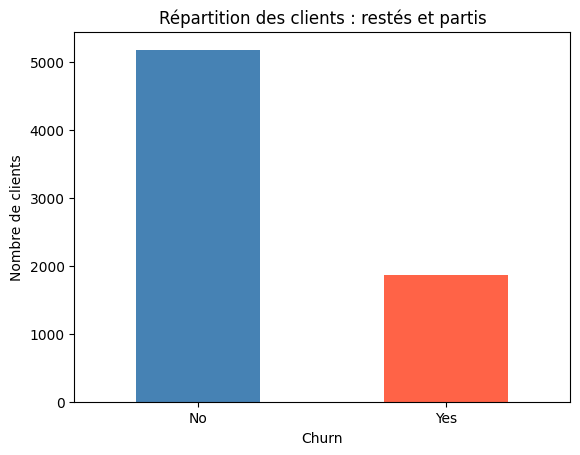

In [11]:
df["Churn"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Répartition des clients : restés et partis")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=0)
plt.savefig("images/01_repartition_churn.png", dpi=150, bbox_inches="tight")
plt.show()

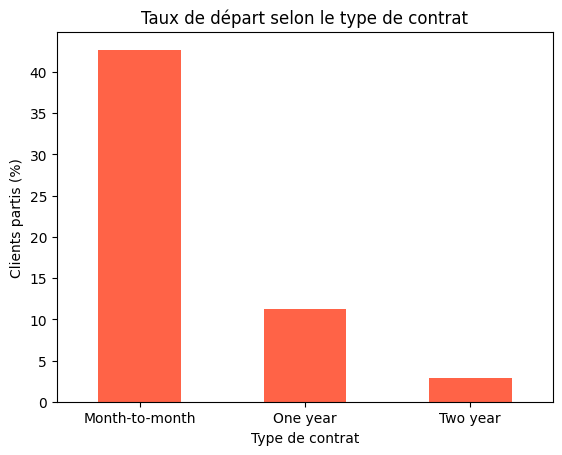

In [28]:
taux_depart("Contract").plot(kind="bar", color="tomato")
plt.title("Taux de départ selon le type de contrat")
plt.ylabel("Clients partis (%)")
plt.xlabel("Type de contrat")
plt.xticks(rotation=0)
plt.savefig("images/02_depart_par_contrat.png", dpi=150, bbox_inches="tight")
plt.show()

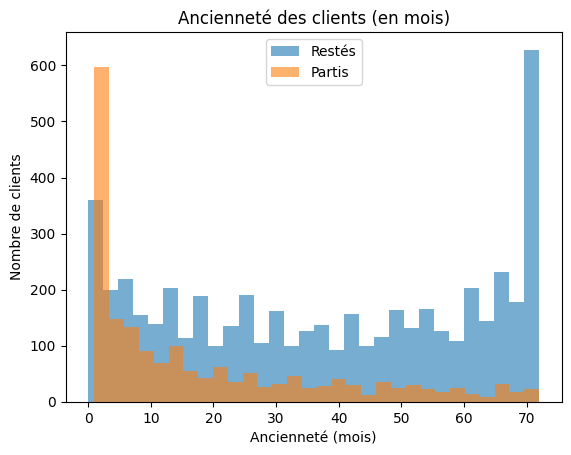

In [29]:
plt.hist(df[df["Churn"] == "No"]["tenure"], bins=30, alpha=0.6, label="Restés")
plt.hist(df[df["Churn"] == "Yes"]["tenure"], bins=30, alpha=0.6, label="Partis")
plt.title("Ancienneté des clients (en mois)")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Nombre de clients")
plt.legend()
plt.savefig("images/03_anciennete.png", dpi=150, bbox_inches="tight")
plt.show()

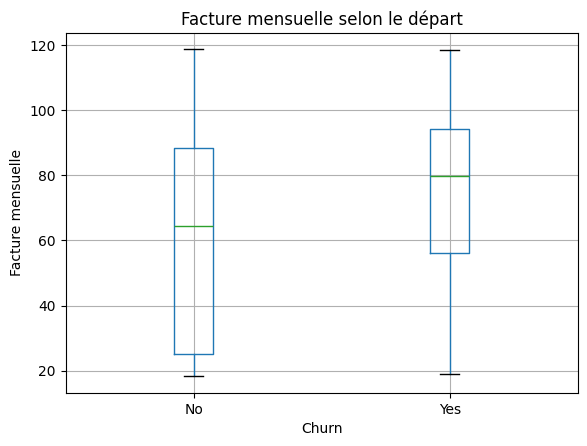

In [30]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Facture mensuelle selon le départ")
plt.suptitle("")
plt.ylabel("Facture mensuelle")
plt.savefig("images/04_facture_mensuelle.png", dpi=150, bbox_inches="tight")
plt.show()

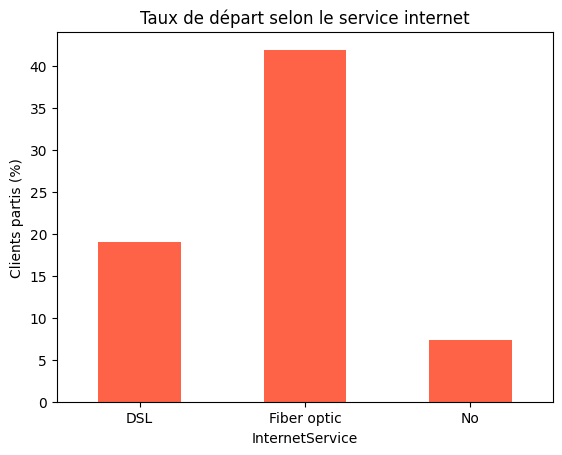

In [31]:
taux_depart("InternetService").plot(kind="bar", color="tomato")
plt.title("Taux de départ selon le service internet")
plt.ylabel("Clients partis (%)")
plt.xticks(rotation=0)
plt.savefig("images/05_depart_par_internet.png", dpi=150, bbox_inches="tight")
plt.show()

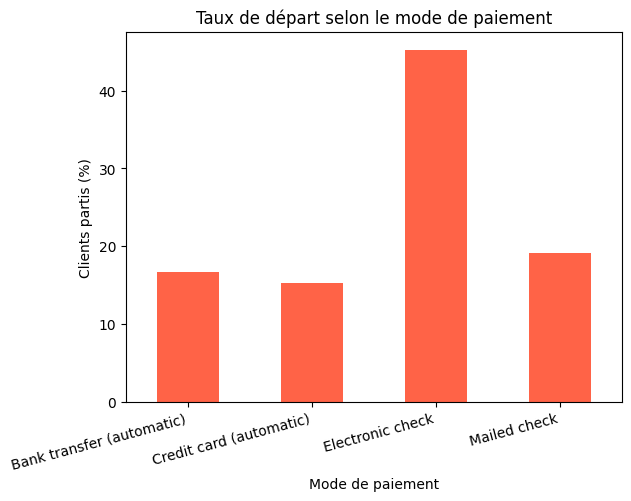

In [32]:
taux_depart("PaymentMethod").plot(kind="bar", color="tomato")
plt.title("Taux de départ selon le mode de paiement")
plt.ylabel("Clients partis (%)")
plt.xlabel("Mode de paiement")
plt.xticks(rotation=15, ha="right")
plt.savefig("images/06_depart_par_paiement.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())

0


In [34]:
data = df.copy()
data = data.drop(columns=["customerID"])
print(data.shape)

(7043, 20)


In [35]:
colonnes_services = ["MultipleLines", "OnlineSecurity", "OnlineBackup",
                     "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

for col in colonnes_services:
    data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

print(data["OnlineSecurity"].value_counts())

OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64


In [36]:
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
print(data["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [37]:
X = data.drop(columns=["Churn"])
y = data["Churn"]
print(X.shape, y.shape)

(7043, 19) (7043,)


In [38]:
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)
X.head()

(7043, 23)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0


In [39]:
print(X.dtypes.value_counts())

int64      21
float64     2
Name: count, dtype: int64


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)

Train : (5634, 23) (5634,)
Test  : (1409, 23) (1409,)


In [41]:
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [42]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(5634, 23) (1409, 23) (5634,) (1409,)


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
import numpy as np

# Remplacer les NaN restants dans les données standardisées par 0
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_train_s_clean = imputer.fit_transform(X_train_s)
X_test_s_clean = imputer.transform(X_test_s)

modele = LogisticRegression(max_iter=1000, random_state=42)
modele.fit(X_train_s_clean, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [45]:
print(X_train.isnull().sum().sum())
print(X_train["TotalCharges"].isnull().sum())

0
0


In [46]:
import numpy as np

print("NaN dans X_train   :", X_train.isnull().sum().sum())
print("NaN dans X_train_s :", np.isnan(X_train_s).sum())
print("Formes :", X_train.shape, X_train_s.shape)

NaN dans X_train   : 0
NaN dans X_train_s : 0
Formes : (5634, 23) (5634, 23)


In [47]:
from sklearn.linear_model import LogisticRegression

modele = LogisticRegression(max_iter=1000, random_state=42)
modele.fit(X_train_s, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Données propres
df["TotalCharges"] = df["TotalCharges"].fillna(0)
data = df.copy().drop(columns=["customerID"])

# 2. Fusion des modalités "No internet/phone service"
colonnes_services = ["MultipleLines", "OnlineSecurity", "OnlineBackup",
                     "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for col in colonnes_services:
    data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

# 3. Cible en 0/1, puis séparation X / y
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
X = data.drop(columns=["Churn"])
y = data["Churn"]

# 4. One-hot
X = pd.get_dummies(X, drop_first=True, dtype=int)

# 5. Train / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Contrôles
print("NaN dans X :", X.isnull().sum().sum())
print("NaN dans y :", y.isnull().sum())
print(X.shape, X_train.shape, X_test.shape)

# 7. Mise à l'échelle (calculée sur le train uniquement) et entraînement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

modele = LogisticRegression(max_iter=1000, random_state=42)
modele.fit(X_train_s, y_train)

NaN dans X : 0
NaN dans y : 0
(7043, 23) (5634, 23) (1409, 23)


LogisticRegression(max_iter=1000, random_state=42)

In [50]:
y_pred = modele.predict(X_test_s)
y_proba = modele.predict_proba(X_test_s)[:, 1]

comparaison = pd.DataFrame({
    "vrai_resultat": y_test.values[:10],
    "proba_depart": y_proba[:10].round(2),
    "prediction": y_pred[:10]
})
comparaison

,vrai_resultat,proba_depart,prediction
0,0,0.05,0
1,0,0.68,1
2,0,0.06,0
3,0,0.41,0
4,0,0.02,0
5,0,0.60,1
6,0,0.45,0
7,0,0.13,0
8,0,0.00,0
9,1,0.39,0


In [51]:
print((y_pred == y_test).mean())

coefficients = pd.Series(modele.coef_[0], index=X.columns).sort_values()
print(coefficients.head(5))
print(coefficients.tail(5))

0.8069552874378992
tenure               -1.254069
MonthlyCharges       -0.842827
InternetService_No   -0.619421
Contract_Two year    -0.586311
Contract_One year    -0.284816
dtype: float64
MultipleLines_Yes              0.210185
StreamingTV_Yes                0.244376
StreamingMovies_Yes            0.244573
TotalCharges                   0.530698
InternetService_Fiber optic    0.744585
dtype: float64


In [52]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[926 109]
 [163 211]]


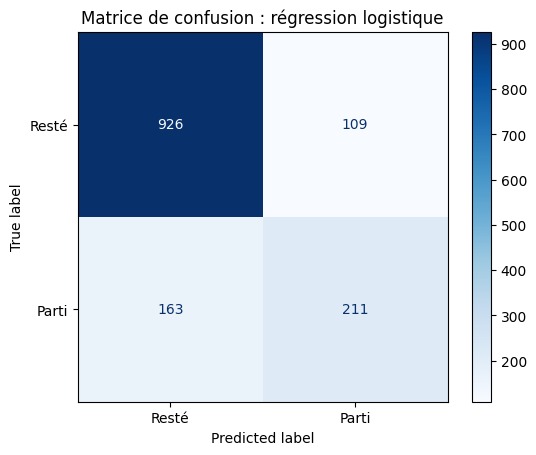

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(cm, display_labels=["Resté", "Parti"]).plot(cmap="Blues")
plt.title("Matrice de confusion : régression logistique")
plt.savefig("images/08_matrice_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [54]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Resté", "Parti"]))

              precision    recall  f1-score   support

       Resté       0.85      0.89      0.87      1035
       Parti       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

